In [1]:
!nvidia-smi

Wed Sep 30 07:06:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%pip install -q -U torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124

In [3]:
%pip install -q ultralytics opencv-python pillow requests rapidfuzz matplotlib pandas tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 5.0 MB/s eta 0:00:00


In [4]:
%pip install -q paddlepaddle==3.2.0
%pip install -q paddleocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 189.0/189.0 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 8.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 6.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.8/146.8 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 759.5/759.5 kB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.2/67.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3

In [5]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [6]:
import torch
import cv2
import numpy as np

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch: 2.11.0+cu128
OpenCV: 4.10.0
NumPy: 2.1.3
CUDA available: True
GPU: Tesla T4


In [7]:
from pathlib import Path
import os
import json
import re
import unicodedata
import math

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from ultralytics import YOLO
from rapidfuzz import fuzz
import requests

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [8]:
!nvidia-smi

Wed Sep 30 07:07:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
%pip install -q -U pip setuptools wheel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 59.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cu128 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.


In [10]:
%pip install -q -U ultralytics
%pip install -q -U paddleocr
%pip install -q -U paddlepaddle
%pip install -q -U rapidfuzz requests matplotlib "pandas<2.4.0" pillow==10.0.1 tqdm pyyaml

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pillow' when getting requirements to build wheel


In [11]:
import sys
import torch
import cv2
import numpy as np

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu128
CUDA available: True
OpenCV: 4.10.0
NumPy: 2.1.3
GPU: Tesla T4


In [12]:
%pip install -q -U rapidfuzz

In [13]:
from pathlib import Path
from pathlib import PurePosixPath

import os
import re
import json
import math
import random
import shutil
import zipfile
import unicodedata

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from google.colab import files

from ultralytics import YOLO
from rapidfuzz import fuzz

import requests

In [14]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Seed set to:", SEED)

Seed set to: 42


In [15]:
BASE_DIR = Path("/content")

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
MODEL_DIR = BASE_DIR / "models"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Base directory:", BASE_DIR)

Base directory: /content


In [16]:
uploaded = files.upload()

uploaded_files = list(uploaded.keys())

print("Uploaded files:")
for file_name in uploaded_files:
    print(file_name)

Saving books-1.zip to books-1.zip
Uploaded files:
books-1.zip


In [17]:
zip_files = [
    Path(name)
    for name in uploaded_files
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file was uploaded."
    )

ZIP_PATH = BASE_DIR / zip_files[0]

print("Using ZIP:")
print(ZIP_PATH)

Using ZIP:
/content/books-1.zip


In [18]:
EXTRACT_DIR = DATA_DIR / "books_dataset"

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)

EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zip_ref:

    zip_ref.extractall(
        EXTRACT_DIR
    )

print("Dataset extracted to:")
print(EXTRACT_DIR)

Dataset extracted to:
/content/data/books_dataset


In [19]:
def find_dataset_root(base_dir):

    candidates = []

    for path in base_dir.rglob("*"):

        if not path.is_dir():
            continue

        required = [
            path / "train",
            path / "valid",
            path / "test"
        ]

        if all(
            folder.exists()
            for folder in required
        ):
            candidates.append(path)

    if not candidates:
        raise FileNotFoundError(
            "Could not find dataset root containing "
            "train, valid and test folders."
        )

    # Select the shallowest match.
    candidates.sort(
        key=lambda p: len(p.parts)
    )

    return candidates[0]


DATASET_ROOT = find_dataset_root(
    EXTRACT_DIR
)

print("Dataset root:")
print(DATASET_ROOT)

Dataset root:
/content/data/books_dataset/books-1


In [20]:
print("Dataset structure:\n")

for path in DATASET_ROOT.iterdir():

    print(
        path.name,
        "/"
        if path.is_dir()
        else ""
    )

    if path.is_dir():

        for child in path.iterdir():

            print(
                "   ",
                child.name,
                "/"
                if child.is_dir()
                else ""
            )

Dataset structure:

README.roboflow.txt 
test /
    labels /
    images /
valid /
    labels /
    images /
README.dataset.txt 
train /
    labels /
    images /
data.yaml 


In [21]:
for split in [
    "train",
    "valid",
    "test"
]:

    images_dir = (
        DATASET_ROOT
        / split
        / "images"
    )

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    print(
        f"{split}:"
    )

    print(
        "  images:",
        images_dir.exists()
    )

    print(
        "  labels:",
        labels_dir.exists()
    )

train:
  images: True
  labels: True
valid:
  images: True
  labels: True
test:
  images: True
  labels: True


In [22]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp"
}


def get_images(folder):

    return [
        p
        for p in folder.iterdir()
        if p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]


for split in [
    "train",
    "valid",
    "test"
]:

    images_dir = (
        DATASET_ROOT
        / split
        / "images"
    )

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    images = get_images(
        images_dir
    )

    labels = list(
        labels_dir.glob("*.txt")
    )

    print(
        f"{split:6s} "
        f"images={len(images):5d} "
        f"labels={len(labels):5d}"
    )

train  images=  422 labels=  422
valid  images=  119 labels=  119
test   images=   69 labels=   69


In [23]:
def check_split(split):

    images_dir = (
        DATASET_ROOT
        / split
        / "images"
    )

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    images = get_images(
        images_dir
    )

    labels = list(
        labels_dir.glob("*.txt")
    )

    image_stems = {
        p.stem
        for p in images
    }

    label_stems = {
        p.stem
        for p in labels
    }

    missing_labels = (
        image_stems - label_stems
    )

    missing_images = (
        label_stems - image_stems
    )

    return (
        missing_labels,
        missing_images
    )


for split in [
    "train",
    "valid",
    "test"
]:

    missing_labels, missing_images = (
        check_split(split)
    )

    print(
        f"\n{split}"
    )

    print(
        "Images without labels:",
        len(missing_labels)
    )

    print(
        "Labels without images:",
        len(missing_images)
    )

    if missing_labels:
        print(
            "Examples:",
            list(missing_labels)[:5]
        )

    if missing_images:
        print(
            "Examples:",
            list(missing_images)[:5]
        )


train
Images without labels: 0
Labels without images: 0

valid
Images without labels: 0
Labels without images: 0

test
Images without labels: 0
Labels without images: 0


In [24]:
def get_class_ids(
    labels_dir
):

    class_ids = set()

    for label_file in labels_dir.glob(
        "*.txt"
    ):

        lines = label_file.read_text().splitlines()

        for line in lines:

            parts = line.split()

            if len(parts) < 5:
                continue

            class_id = int(
                float(parts[0])
            )

            class_ids.add(
                class_id
            )

    return sorted(
        class_ids
    )


all_class_ids = set()

for split in [
    "train",
    "valid",
    "test"
]:

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    ids = get_class_ids(
        labels_dir
    )

    print(
        split,
        "class IDs:",
        ids
    )

    all_class_ids.update(
        ids
    )

print(
    "\nAll class IDs:",
    sorted(all_class_ids)
)

train class IDs: [0]
valid class IDs: [0]
test class IDs: [0]

All class IDs: [0]


In [25]:
if sorted(all_class_ids) == [1]:

    print(
        "Remapping class 1 → class 0..."
    )

    for split in [
        "train",
        "valid",
        "test"
    ]:

        labels_dir = (
            DATASET_ROOT
            / split
            / "labels"
        )

        for label_file in labels_dir.glob(
            "*.txt"
        ):

            lines = (
                label_file
                .read_text()
                .splitlines()
            )

            new_lines = []

            for line in lines:

                parts = line.split()

                if len(parts) != 5:
                    continue

                parts[0] = "0"

                new_lines.append(
                    " ".join(parts)
                )

            label_file.write_text(
                "\n".join(new_lines),
                encoding="utf-8"
            )

    print(
        "Done."
    )

else:

    print(
        "No class-ID remapping required."
    )

No class-ID remapping required.


In [26]:
yaml_path = BASE_DIR / "book_spines.yaml"

yaml_content = f"""
path: {DATASET_ROOT}

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine
"""

yaml_path.write_text(
    yaml_content.strip(),
    encoding="utf-8"
)

print(
    yaml_path.read_text(
        encoding="utf-8"
    )
)

path: /content/data/books_dataset/books-1

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine


In [27]:
train_images_dir = (
    DATASET_ROOT
    / "train"
    / "images"
)

train_labels_dir = (
    DATASET_ROOT
    / "train"
    / "labels"
)

train_images = get_images(
    train_images_dir
)

sample_image = random.choice(
    train_images
)

sample_label = (
    train_labels_dir
    / f"{sample_image.stem}.txt"
)

print(
    "Image:",
    sample_image
)

print(
    "Label:",
    sample_label
)

Image: /content/data/books_dataset/books-1/train/images/crop-327_png.rf.1a054756b0bb162c6d791c2159d9ed32.jpg
Label: /content/data/books_dataset/books-1/train/labels/crop-327_png.rf.1a054756b0bb162c6d791c2159d9ed32.txt


In [28]:
def draw_yolo_annotations(
    image_path,
    label_path
):

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        raise ValueError(
            "Could not load image."
        )

    h, w = image.shape[:2]

    if label_path.exists():

        lines = (
            label_path
            .read_text()
            .splitlines()
        )

        for line in lines:

            parts = line.split()

            if len(parts) != 5:
                continue

            class_id, xc, yc, bw, bh = (
                map(
                    float,
                    parts
                )
            )

            x1 = int(
                (xc - bw / 2) * w
            )

            y1 = int(
                (yc - bh / 2) * h
            )

            x2 = int(
                (xc + bw / 2) * w
            )

            y2 = int(
                (yc + bh / 2) * h
            )

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            cv2.putText(
                image,
                "book_spine",
                (
                    x1,
                    max(25, y1 - 7)
                ),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.65,
                (0, 255, 0),
                2
            )

    return image

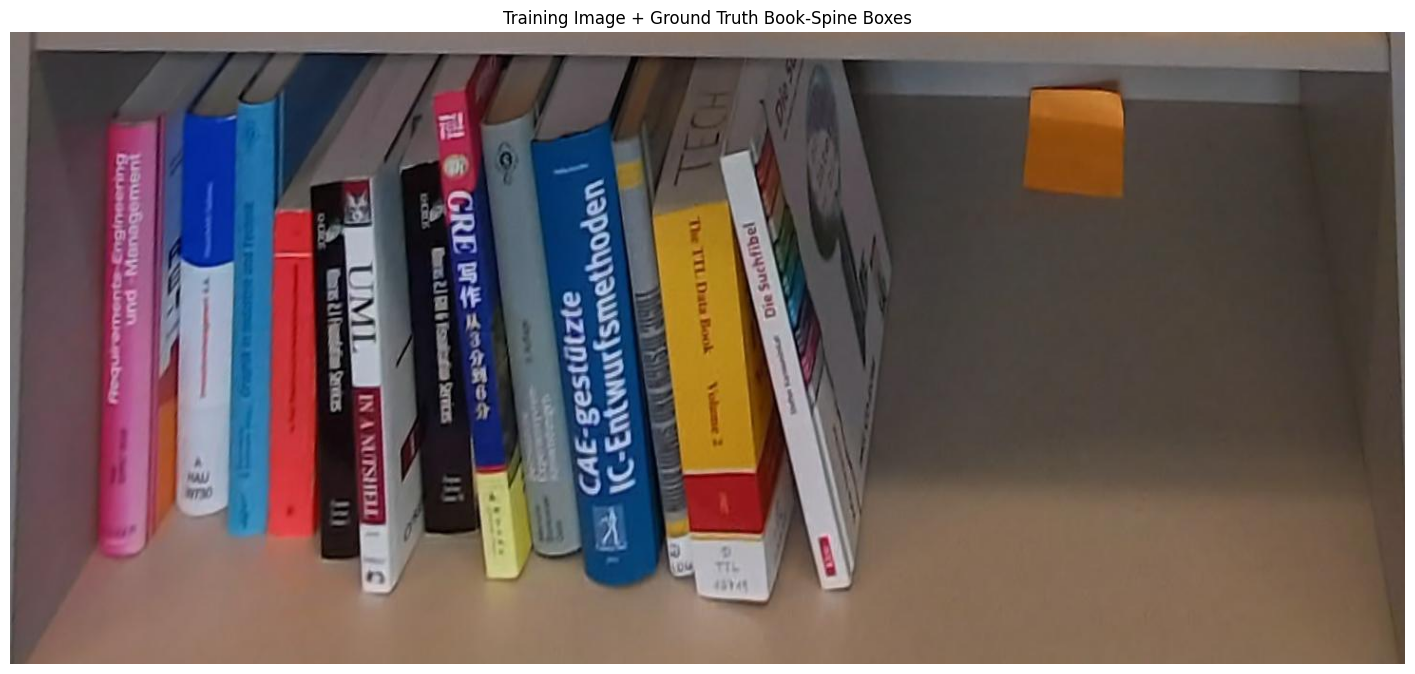

In [29]:
annotated = draw_yolo_annotations(
    sample_image,
    sample_label
)

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(18, 10)
)

plt.imshow(
    annotated_rgb
)

plt.axis("off")

plt.title(
    "Training Image + Ground Truth Book-Spine Boxes"
)

plt.show()

In [30]:
for _ in range(5):

    image_path = random.choice(
        train_images
    )

    label_path = (
        train_labels_dir
        / f"{image_path.stem}.txt"
    )

    print("=" * 80)

    print("IMAGE:", image_path.name)
    print("LABEL:", label_path.name)

    if label_path.exists():

        content = (
            label_path
            .read_text()
            .strip()
        )

        print("CONTENT:")

        if content:
            print(content)
        else:
            print("EMPTY LABEL FILE")

    else:

        print("LABEL FILE DOES NOT EXIST")

IMAGE: crop-158_png.rf.71a774466c5ea347c6074b8c8f49314d.jpg
LABEL: crop-158_png.rf.71a774466c5ea347c6074b8c8f49314d.txt
CONTENT:
0 0.8723343109756098 0.956825401225115 0.8836126913109756 0.9669004762633998 0.8973973361280488 0.9719380612557428 0.9093022347560975 0.9731974333843798 0.91682121875 0.9669004762633998 0.8967707217987805 0.14829597243491577 0.8483660457317074 0.14978457274119447 0.8723343109756098 0.956825401225115
0 0.9716640457317073 1 0.97947878125 0.9958665191424196 0.9888774153963416 0.9820132327718224 0.9707066653963414 0.20370919448698319 0.9631877766768293 0.21126554977029094 0.9512828780487804 0.21504373813169986 0.9280995030487804 0.22008130015313934 0.9080491021341464 0.21126554977029094 0.9255932393292683 0.9731974333843798 0.9393778841463415 0.9883101898928024 0.950029650152439 0.9958665191424196 0.9615460594512195 1 0.9716640457317073 1
0 0.5158127698170731 0.6369398820826953 0.8397523971036586 0.9429720168453292 0.8554138201219512 0.8404928422664625 0.53648978

In [31]:
def validate_segmentation_label_file(label_path):

    errors = []

    lines = (
        label_path
        .read_text()
        .splitlines()
    )

    for line_number, line in enumerate(
        lines,
        start=1
    ):

        if not line.strip():
            continue

        parts = line.split()

        # At least:
        # class_id + 3 (x,y) points
        if len(parts) < 7:

            errors.append(
                f"Line {line_number}: "
                "not enough polygon coordinates"
            )

            continue

        # After class ID, coordinate count
        # must be even.
        coordinate_count = len(parts) - 1

        if coordinate_count % 2 != 0:

            errors.append(
                f"Line {line_number}: "
                "odd number of polygon coordinates"
            )

            continue

        try:

            class_id = int(
                float(parts[0])
            )

            coordinates = [
                float(x)
                for x in parts[1:]
            ]

        except ValueError:

            errors.append(
                f"Line {line_number}: "
                "contains non-numeric values"
            )

            continue

        if class_id != 0:

            errors.append(
                f"Line {line_number}: "
                f"class={class_id}, "
                "expected 0"
            )

        for value in coordinates:

            if not 0 <= value <= 1:

                errors.append(
                    f"Line {line_number}: "
                    f"coordinate {value} "
                    "outside [0, 1]"
                )

    return errors

In [32]:
errors = validate_segmentation_label_file(
    sample_label
)

if errors:

    print("ERRORS FOUND:\n")

    for error in errors:
        print(error)

else:

    print(
        "Segmentation label is valid."
    )

Segmentation label is valid.


In [33]:
def count_segmentation_annotations(
    labels_dir
):

    count = 0

    for label_file in labels_dir.glob(
        "*.txt"
    ):

        lines = (
            label_file
            .read_text()
            .splitlines()
        )

        count += sum(
            1
            for line in lines
            if line.strip()
        )

    return count


for split in [
    "train",
    "valid",
    "test"
]:

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    print(
        split,
        "book polygons:",
        count_segmentation_annotations(
            labels_dir
        )
    )

train book polygons: 4592
valid book polygons: 1292
test book polygons: 725


In [34]:
def draw_segmentation_annotations(
    image_path,
    label_path
):

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        raise ValueError(
            "Could not load image."
        )

    h, w = image.shape[:2]

    if not label_path.exists():

        print(
            "Label file does not exist."
        )

        return image

    lines = (
        label_path
        .read_text()
        .splitlines()
    )

    for index, line in enumerate(
        lines,
        start=1
    ):

        if not line.strip():
            continue

        parts = line.split()

        if len(parts) < 7:
            continue

        coordinates = np.array(
            [
                float(x)
                for x in parts[1:]
            ],
            dtype=np.float32
        )

        # Convert normalized coordinates
        # to pixel coordinates.

        points = coordinates.reshape(
            -1,
            2
        )

        points[:, 0] *= w
        points[:, 1] *= h

        points = points.astype(
            np.int32
        )

        # Draw polygon
        cv2.polylines(
            image,
            [points],
            isClosed=True,
            color=(0, 255, 0),
            thickness=3
        )

        # Draw object number
        center = points.mean(
            axis=0
        ).astype(
            np.int32
        )

        cv2.putText(
            image,
            f"Book {index}",
            tuple(center),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    return image

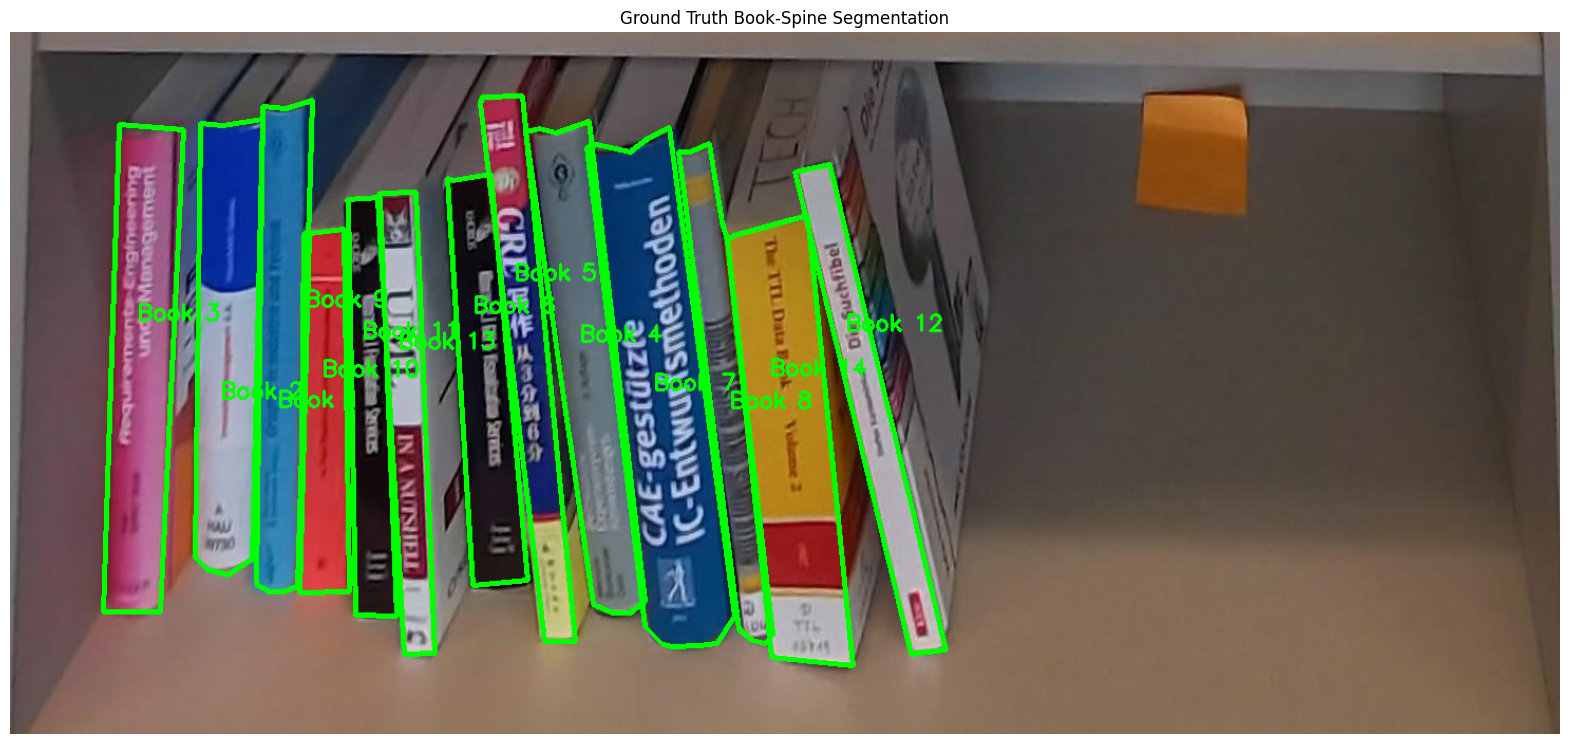

In [35]:
annotated = (
    draw_segmentation_annotations(
        sample_image,
        sample_label
    )
)

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(20, 12)
)

plt.imshow(
    annotated_rgb
)

plt.axis("off")

plt.title(
    "Ground Truth Book-Spine Segmentation"
)

plt.show()

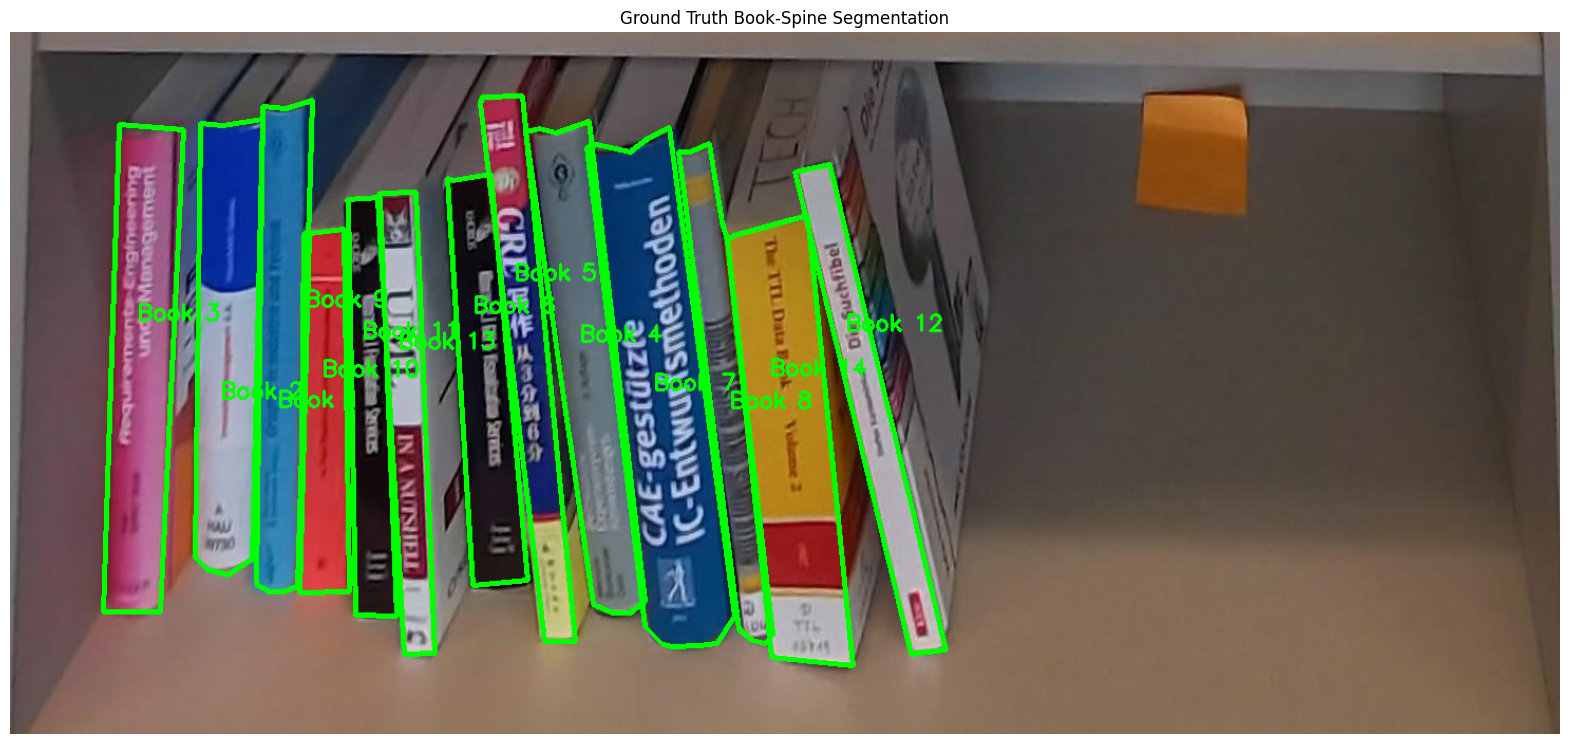

In [36]:
annotated = (
    draw_segmentation_annotations(
        sample_image,
        sample_label
    )
)

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(20, 12)
)

plt.imshow(
    annotated_rgb
)

plt.axis("off")

plt.title(
    "Ground Truth Book-Spine Segmentation"
)

plt.show()

In [37]:
def inspect_polygon_points(
    label_path
):

    lines = (
        label_path
        .read_text()
        .splitlines()
    )

    for index, line in enumerate(
        lines,
        start=1
    ):

        parts = line.split()

        if not parts:
            continue

        coordinates = parts[1:]

        number_of_points = (
            len(coordinates) // 2
        )

        print(
            f"Book {index}: "
            f"{number_of_points} polygon points"
        )


inspect_polygon_points(
    sample_label
)

Book 1: 8 polygon points
Book 2: 8 polygon points
Book 3: 5 polygon points
Book 4: 9 polygon points
Book 5: 6 polygon points
Book 6: 6 polygon points
Book 7: 12 polygon points
Book 8: 10 polygon points
Book 9: 4 polygon points
Book 10: 5 polygon points
Book 11: 6 polygon points
Book 12: 6 polygon points
Book 13: 6 polygon points
Book 14: 6 polygon points


In [38]:
model = YOLO(
    "yolo26n-seg.pt"
)

In [39]:
yaml_path = BASE_DIR / "book_spines.yaml"

yaml_content = f"""
path: {DATASET_ROOT}

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine
"""

yaml_path.write_text(
    yaml_content.strip(),
    encoding="utf-8"
)

print(
    yaml_path.read_text()
)

path: /content/data/books_dataset/books-1

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine


In [40]:
IMG_SIZE = 960
EPOCHS = 100

seg_model = YOLO(
    "yolo26n-seg.pt"
)

In [41]:
import torch

if torch.cuda.is_available():

    DEVICE = 0

    print(
        "Training on:",
        torch.cuda.get_device_name(0)
    )

else:

    DEVICE = "cpu"

    print(
        "WARNING: GPU not available."
    )

Training on: Tesla T4


In [42]:
seg_train_results = seg_model.train(
    data=str(yaml_path),

    epochs=EPOCHS,

    imgsz=IMG_SIZE,

    batch=-1,

    device=DEVICE,

    patience=20,

    workers=2,

    cache=False,

    amp=True,

    seed=SEED,

    project="/content/runs",

    name="book_spine_segmentation",

    exist_ok=True,

    plots=True
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/book_spines.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=book_spine_segmentation, nbs=64, nms=None, opset=None, opti

In [64]:
from pathlib import Path

best_files = list(
    Path("/content").rglob("best.pt")
)

print(
    "Number of best.pt files found:",
    len(best_files)
)

for path in best_files:
    print(path)

Number of best.pt files found: 1
/content/runs/book_spine_segmentation/weights/best.pt


In [65]:
from pathlib import Path

BASE_DIR = Path("/content")

all_pt_files = list(
    BASE_DIR.rglob("*.pt")
)

print(
    "All .pt files found:",
    len(all_pt_files)
)

for path in all_pt_files:
    print(path)

All .pt files found: 4
/content/yolo26n-seg.pt
/content/weights/yolo26n.pt
/content/runs/book_spine_segmentation/weights/best.pt
/content/runs/book_spine_segmentation/weights/last.pt


In [66]:
if not best_files:
    raise FileNotFoundError(
        "No best.pt found. "
        "Make sure the training cell completed successfully."
    )

# If there are multiple runs, use the newest one.
best_files.sort(
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

BEST_MODEL_PATH = best_files[0]

print(
    "Selected best model:"
)

print(
    BEST_MODEL_PATH
)

Selected best model:
/content/runs/book_spine_segmentation/weights/best.pt


In [67]:
from ultralytics import YOLO

book_segmenter = YOLO(
    str(BEST_MODEL_PATH)
)

print(
    "Model loaded successfully."
)

print(
    "Task:",
    book_segmenter.task
)

print(
    "Classes:",
    book_segmenter.names
)

Model loaded successfully.
Task: segment
Classes: {0: 'book_spine'}


In [68]:
val_metrics = book_segmenter.val(
    data=str(yaml_path),
    split="val",
    imgsz=IMG_SIZE,
    device=DEVICE
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,689,079 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1822.1±507.5 MB/s, size: 62.4 KB)
val: Scanning /content/dataset/books-1/valid/labels.cache... 119 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 119/119 31.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.1it/s 7.2s
                   all        119       1292      0.982      0.978      0.993      0.887      0.977      0.973      0.991      0.796
Speed: 5.3ms preprocess, 14.5ms inference, 0.0ms loss, 7.1ms postprocess per image
Results saved to /content/runs/segment/val


In [69]:
print("========== VALIDATION ==========")

print("\nBOX METRICS")

print(
    "Precision:",
    round(val_metrics.box.mp, 4)
)

print(
    "Recall:",
    round(val_metrics.box.mr, 4)
)

print(
    "mAP50:",
    round(val_metrics.box.map50, 4)
)

print(
    "mAP50-95:",
    round(val_metrics.box.map, 4)
)

print("\nMASK METRICS")

print(
    "mAP50:",
    round(val_metrics.seg.map50, 4)
)

print(
    "mAP50-95:",
    round(val_metrics.seg.map, 4)
)

========== VALIDATION ==========

BOX METRICS
Precision: 0.982
Recall: 0.9783
mAP50: 0.9933
mAP50-95: 0.8868

MASK METRICS
mAP50: 0.9908
mAP50-95: 0.796


In [70]:
test_metrics = book_segmenter.val(
    data=str(yaml_path),
    split="test",
    imgsz=IMG_SIZE,
    device=DEVICE
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,689,079 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1364.6±520.7 MB/s, size: 122.1 KB)
val: Scanning /content/dataset/books-1/test/labels... 69 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 69/69 1.3Kit/s 0.1s
val: New cache created: /content/dataset/books-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.2s/it 5.8s
                   all         69        725      0.976       0.99      0.993      0.872      0.973      0.987      0.993      0.803
Speed: 8.4ms preprocess, 13.3ms inference, 0.0ms loss, 7.4ms postprocess per image
Results saved to /content/runs/segment/val-2


In [71]:
print("========== TEST ==========")

print("\nBOX METRICS")

print(
    "Precision:",
    round(test_metrics.box.mp, 4)
)

print(
    "Recall:",
    round(test_metrics.box.mr, 4)
)

print(
    "mAP50:",
    round(test_metrics.box.map50, 4)
)

print(
    "mAP50-95:",
    round(test_metrics.box.map, 4)
)

print("\nMASK METRICS")

print(
    "mAP50:",
    round(test_metrics.seg.map50, 4)
)

print(
    "mAP50-95:",
    round(test_metrics.seg.map, 4)
)

========== TEST ==========

BOX METRICS
Precision: 0.9755
Recall: 0.9902
mAP50: 0.9929
mAP50-95: 0.8723

MASK METRICS
mAP50: 0.9925
mAP50-95: 0.8029


In [72]:
import pandas as pd

RESULTS_CSV = (
    BEST_MODEL_PATH.parent.parent
    / "results.csv"
)

print(
    "Results file:",
    RESULTS_CSV
)

print(
    "Exists:",
    RESULTS_CSV.exists()
)

results_df = pd.read_csv(
    RESULTS_CSV
)

results_df.head()

Results file: /content/runs/book_spine_segmentation/results.csv
Exists: False


FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/book_spine_segmentation/results.csv'

In [ ]:
results_df.columns = (
    results_df.columns
    .str.strip()
)

print(
    results_df.columns.tolist()
)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    results_df["train/box_loss"],
    label="Train Box Loss"
)

plt.plot(
    results_df["val/box_loss"],
    label="Validation Box Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Book-Spine Detection Box Loss"
)

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    results_df["metrics/mAP50(M)"],
    label="Mask mAP50"
)

plt.plot(
    results_df["metrics/mAP50-95(M)"],
    label="Mask mAP50-95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")

plt.title(
    "Book-Spine Segmentation Performance"
)

plt.legend()
plt.grid(True)

plt.show()

In [73]:
from google.colab import files

uploaded_test = files.upload()

if not uploaded_test:
    raise ValueError(
        "No image was uploaded."
    )

TEST_FILENAME = list(
    uploaded_test.keys()
)[0]

TEST_IMAGE_PATH = (
    Path("/content")
    / TEST_FILENAME
)

print(
    "Testing image:",
    TEST_IMAGE_PATH
)

Saving shelfy.jpg to shelfy.jpg
Testing image: /content/shelfy.jpg


In [74]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

test_image = cv2.imread(
    str(TEST_IMAGE_PATH)
)

if test_image is None:
    raise ValueError(
        "Could not read the uploaded image."
    )

print(
    "Image shape:",
    test_image.shape
)

Image shape: (489, 416, 3)


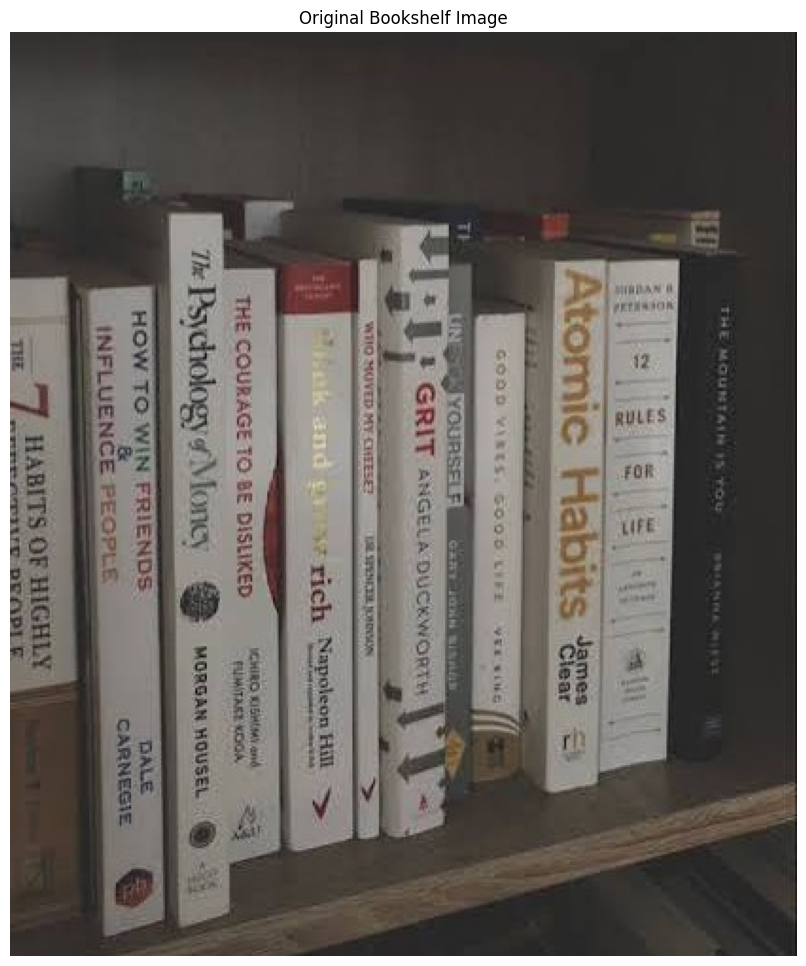

In [75]:
test_rgb = cv2.cvtColor(
    test_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(20, 12)
)

plt.imshow(
    test_rgb
)

plt.axis("off")

plt.title(
    "Original Bookshelf Image"
)

plt.show()

In [76]:
predictions = book_segmenter.predict(
    source=test_image,

    imgsz=IMG_SIZE,

    conf=0.25,

    iou=0.50,

    max_det=300,

    device=DEVICE,

    verbose=False
)

prediction = predictions[0]

print(
    "Inference complete."
)

Inference complete.


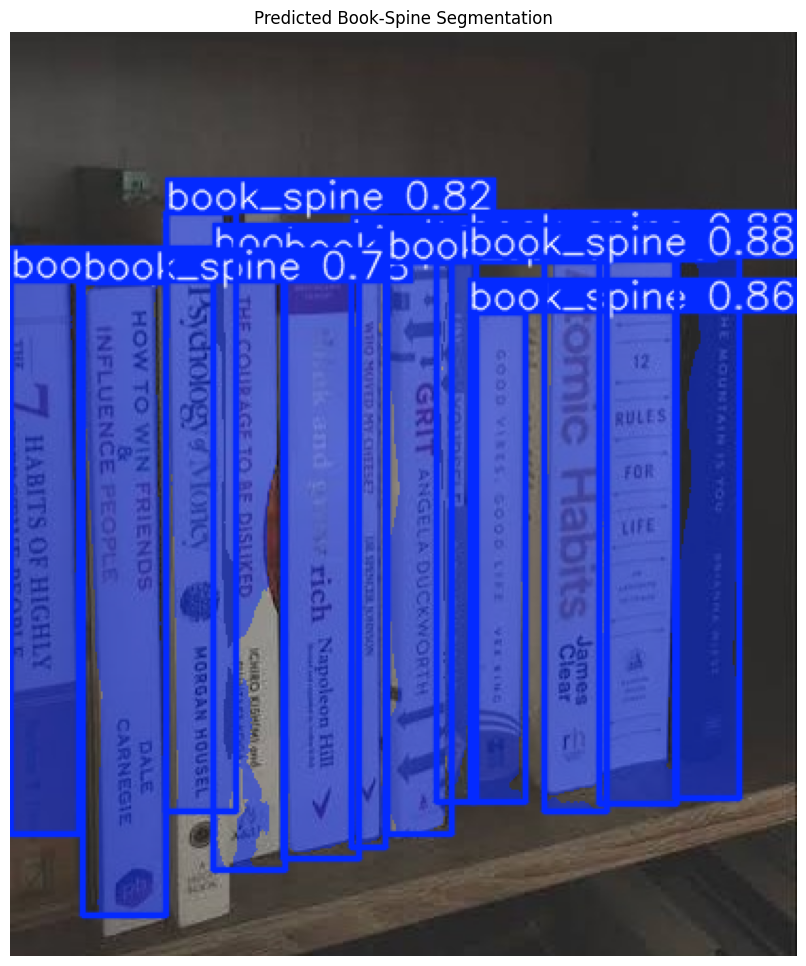

In [77]:
predicted_image = (
    prediction.plot()
)

predicted_rgb = cv2.cvtColor(
    predicted_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(20, 12)
)

plt.imshow(
    predicted_rgb
)

plt.axis("off")

plt.title(
    "Predicted Book-Spine Segmentation"
)

plt.show()

In [78]:
detections = []

if prediction.boxes is None:

    print(
        "No books detected."
    )

else:

    for i in range(
        len(prediction.boxes)
    ):

        box = (
            prediction
            .boxes
            .xyxy[i]
            .cpu()
            .numpy()
        )

        confidence = (
            prediction
            .boxes
            .conf[i]
            .cpu()
            .item()
        )

        x1, y1, x2, y2 = map(
            int,
            box
        )

        detections.append({

            "id":
                i + 1,

            "box":
                (
                    x1,
                    y1,
                    x2,
                    y2
                ),

            "confidence":
                float(confidence)
        })


print(
    "Books detected:",
    len(detections)
)

Books detected: 12


In [79]:
def sort_detections(
    detections
):

    if not detections:
        return []

    items = []

    for item in detections:

        x1, y1, x2, y2 = (
            item["box"]
        )

        items.append({

            **item,

            "center_x":
                (x1 + x2) / 2,

            "center_y":
                (y1 + y2) / 2,

            "height":
                y2 - y1
        })

    median_height = np.median(
        [
            x["height"]
            for x in items
        ]
    )

    row_threshold = (
        median_height * 0.5
    )

    # Top to bottom
    items.sort(
        key=lambda x:
            x["center_y"]
    )

    rows = []

    for item in items:

        assigned = False

        for row in rows:

            row_y = np.mean(
                [
                    x["center_y"]
                    for x in row
                ]
            )

            if abs(
                item["center_y"] - row_y
            ) <= row_threshold:

                row.append(item)

                assigned = True

                break

        if not assigned:

            rows.append(
                [item]
            )

    # Left to right within each shelf
    for row in rows:

        row.sort(
            key=lambda x:
                x["center_x"]
        )

    # Top shelf first
    rows.sort(
        key=lambda row:
            np.mean(
                [
                    x["center_y"]
                    for x in row
                ]
            )
    )

    ordered = []

    book_number = 1

    for row_number, row in enumerate(
        rows,
        start=1
    ):

        for item in row:

            item["id"] = (
                book_number
            )

            item["row"] = (
                row_number
            )

            ordered.append(
                item
            )

            book_number += 1

    return ordered


detections = sort_detections(
    detections
)

In [80]:
for item in detections:

    print(
        f"Book {item['id']:02d} | "
        f"Row {item['row']} | "
        f"Confidence "
        f"{item['confidence']:.3f}"
    )

Book 01 | Row 1 | Confidence 0.733
Book 02 | Row 1 | Confidence 0.783
Book 03 | Row 1 | Confidence 0.819
Book 04 | Row 1 | Confidence 0.770
Book 05 | Row 1 | Confidence 0.772
Book 06 | Row 1 | Confidence 0.665
Book 07 | Row 1 | Confidence 0.795
Book 08 | Row 1 | Confidence 0.734
Book 09 | Row 1 | Confidence 0.861
Book 10 | Row 1 | Confidence 0.875
Book 11 | Row 1 | Confidence 0.879
Book 12 | Row 1 | Confidence 0.723


In [81]:
def crop_book(
    image,
    box,
    padding_ratio=0.02
):

    x1, y1, x2, y2 = box

    h, w = image.shape[:2]

    width = x2 - x1
    height = y2 - y1

    pad_x = int(
        width * padding_ratio
    )

    pad_y = int(
        height * padding_ratio
    )

    x1 = max(
        0,
        x1 - pad_x
    )

    y1 = max(
        0,
        y1 - pad_y
    )

    x2 = min(
        w,
        x2 + pad_x
    )

    y2 = min(
        h,
        y2 + pad_y
    )

    return image[
        y1:y2,
        x1:x2
    ]

In [82]:
CROP_DIR = (
    OUTPUT_DIR /
    "book_crops"
)

CROP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

book_crops = []

for item in detections:

    crop = crop_book(
        test_image,
        item["box"]
    )

    book_crops.append(
        crop
    )

    crop_path = (
        CROP_DIR /
        f"book_{item['id']:03d}.jpg"
    )

    cv2.imwrite(
        str(crop_path),
        crop
    )

print(
    "Created",
    len(book_crops),
    "book crops."
)

Created 12 book crops.


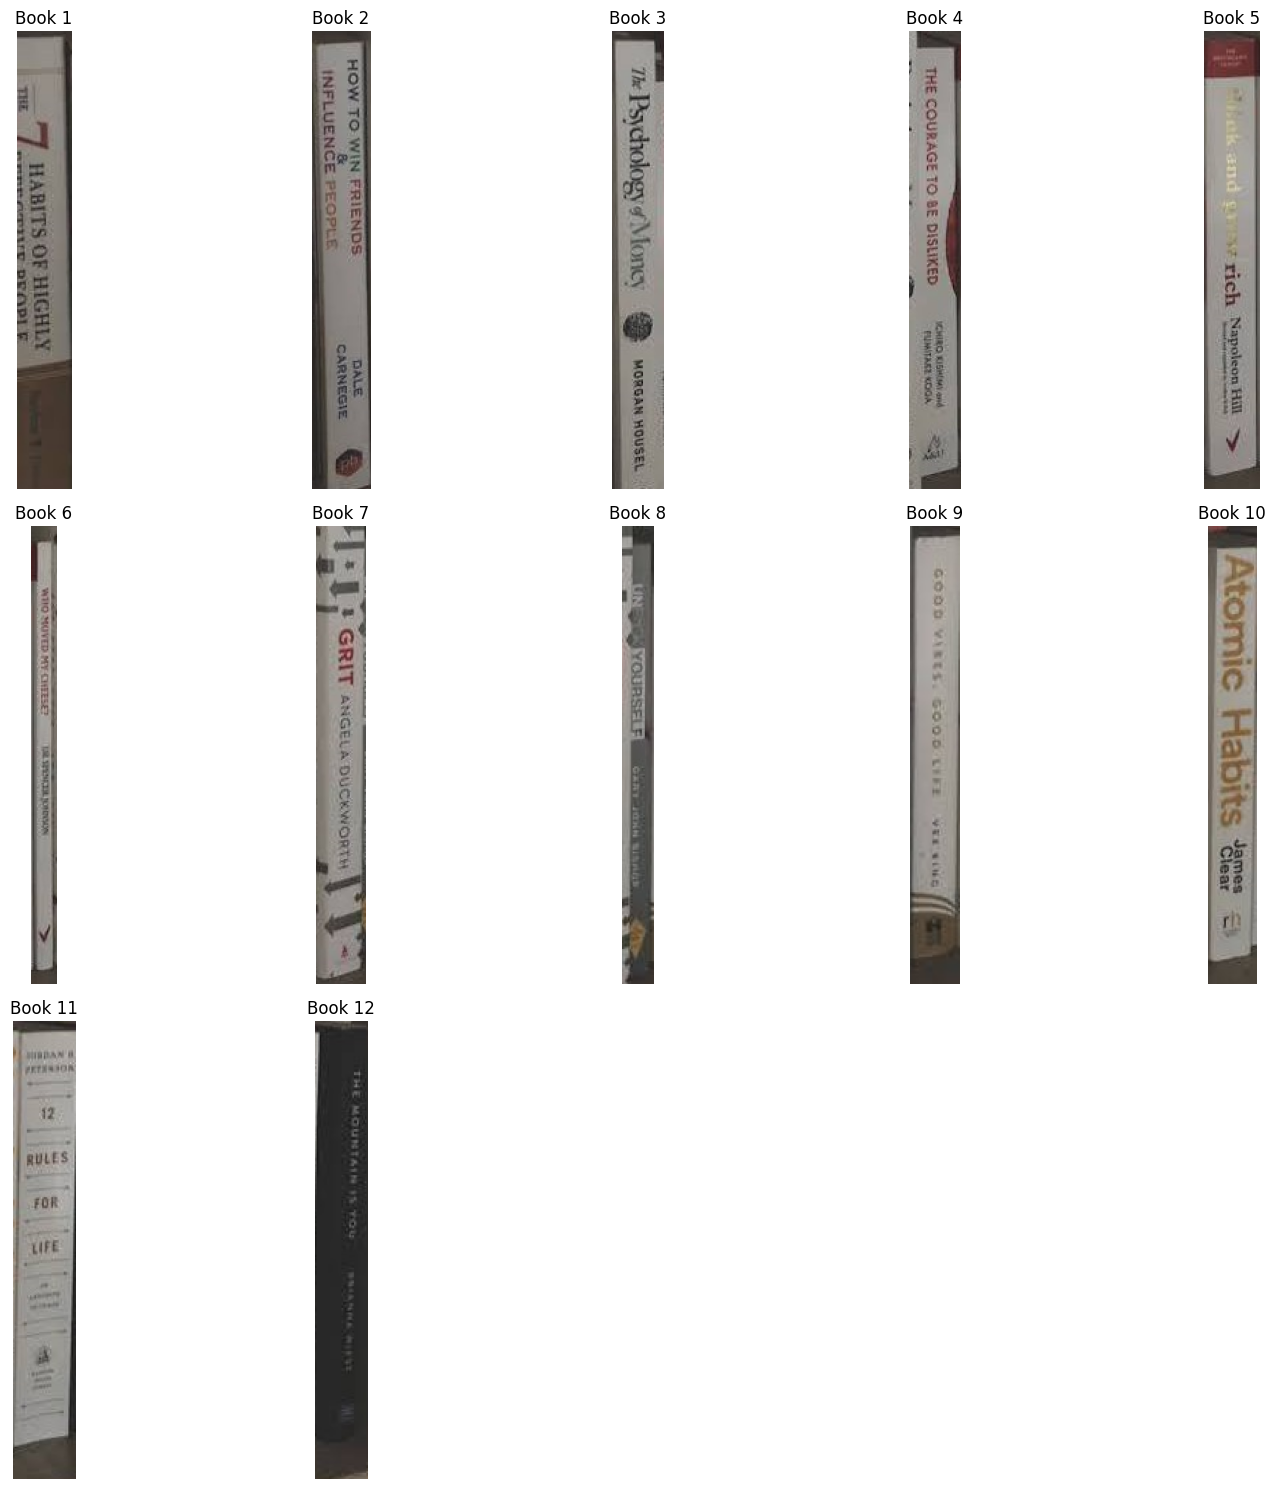

In [83]:
def display_crops(
    crops,
    columns=5
):

    if not crops:
        print("No crops.")
        return

    rows = math.ceil(
        len(crops) / columns
    )

    plt.figure(
        figsize=(
            columns * 3,
            rows * 5
        )
    )

    for i, crop in enumerate(
        crops,
        start=1
    ):

        crop_rgb = cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )

        ax = plt.subplot(
            rows,
            columns,
            i
        )

        ax.imshow(
            crop_rgb
        )

        ax.set_title(
            f"Book {i}"
        )

        ax.axis("off")

    plt.tight_layout()

    plt.show()


display_crops(
    book_crops
)

In [84]:
def upscale_crop(
    crop,
    target_height=800
):

    if crop is None:
        return crop

    h, w = crop.shape[:2]

    if h == 0 or w == 0:
        return crop

    if h >= target_height:
        return crop

    scale = (
        target_height / h
    )

    new_width = int(
        w * scale
    )

    return cv2.resize(
        crop,
        (
            new_width,
            target_height
        ),
        interpolation=cv2.INTER_CUBIC
    )

In [85]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    lang="en",

    use_doc_orientation_classify=False,

    use_doc_unwarping=False,

    use_textline_orientation=True
)

print(
    "PaddleOCR initialized."
)

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.
Using official model (PP-LCNet_x1_0_textline_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('PP-OCRv6_medium_det', None, None)
Using official model (PP-OCRv6_medium_det), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_det`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Creating model: ('PP-OCRv6_medium_rec', None, None)
Using official model (PP-OCRv6_medium_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

PaddleOCR initialized.


In [86]:
import json


def parse_ocr_result(
    result
):

    data = result.json

    if isinstance(
        data,
        str
    ):

        data = json.loads(
            data
        )

    if (
        isinstance(data, dict)
        and "res" in data
    ):

        data = data["res"]

    texts = data.get(
        "rec_texts",
        []
    )

    scores = data.get(
        "rec_scores",
        []
    )

    lines = []

    for text, score in zip(
        texts,
        scores
    ):

        text = str(
            text
        ).strip()

        if not text:
            continue

        lines.append({

            "text":
                text,

            "confidence":
                float(score)
        })

    if not lines:

        return {

            "text":
                "",

            "confidence":
                0.0,

            "lines":
                []
        }

    combined_text = " ".join(
        line["text"]
        for line in lines
    )

    confidence = float(
        np.mean(
            [
                line["confidence"]
                for line in lines
            ]
        )
    )

    return {

        "text":
            combined_text,

        "confidence":
            confidence,

        "lines":
            lines
    }

In [87]:
def ocr_once(
    image
):

    try:

        results = ocr.predict(
            input=image
        )

        if not results:

            return {
                "text": "",
                "confidence": 0.0
            }

        return parse_ocr_result(
            results[0]
        )

    except Exception as e:

        print(
            "OCR error:",
            e
        )

        return {
            "text": "",
            "confidence": 0.0
        }

In [88]:
def ocr_book(
    crop,
    retry_threshold=0.75
):

    crop = upscale_crop(
        crop,
        target_height=800
    )

    # First attempt
    best = ocr_once(
        crop
    )

    best["orientation"] = (
        "original"
    )

    # If OCR is good enough,
    # don't waste time on rotations.
    if (
        best["text"].strip()
        and
        best["confidence"]
        >= retry_threshold
    ):

        return best

    # Difficult crop:
    # try 90-degree rotations.
    variants = {

        "90_clockwise":
            cv2.rotate(
                crop,
                cv2.ROTATE_90_CLOCKWISE
            ),

        "90_counterclockwise":
            cv2.rotate(
                crop,
                cv2.ROTATE_90_COUNTERCLOCKWISE
            )
    }

    for orientation, variant in (
        variants.items()
    ):

        result = ocr_once(
            variant
        )

        if (
            result["text"].strip()
            and
            result["confidence"]
            > best["confidence"]
        ):

            best = {
                **result,
                "orientation":
                    orientation
            }

    return best

In [89]:
from tqdm.auto import tqdm

ocr_outputs = []

for crop in tqdm(
    book_crops,
    desc="Reading book spines"
):

    result = ocr_book(
        crop
    )

    ocr_outputs.append(
        result
    )

Reading book spines:   0%|          | 0/12 [00:00<?, ?it/s]

OCR error: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

OCR error: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

OCR error: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

OCR error: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/paddle/fluid/framework/new_executor/instruction/onednn/onednn_instruction.cc:116)

OCR error: (Unimplemented) ConvertPirAttribute2RuntimeAttribute not support [pir::ArrayAttribute<pir::DoubleAttribute>]  (at /paddle/pad

In [90]:
for i, result in enumerate(
    ocr_outputs,
    start=1
):

    print(
        f"\nBook {i}"
    )

    print(
        "Text:",
        result["text"]
    )

    print(
        "Confidence:",
        round(
            result["confidence"],
            3
        )
    )

    print(
        "Orientation:",
        result["orientation"]
    )

    print(
        "-" * 70
    )


Book 1
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 2
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 3
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 4
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 5
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 6
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 7
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 8
Text: 
Confidence: 0.0
Orientation: original
----------------------------------------------------------------------

Book 9


In [91]:
import paddle

print("PaddlePaddle version:")
print(paddle.__version__)

print("\nCompiled with CUDA:")
print(paddle.is_compiled_with_cuda())

print("\nCurrent Paddle device:")
print(paddle.device.get_device())

PaddlePaddle version:
3.3.1

Compiled with CUDA:
False

Current Paddle device:
cpu


In [92]:
from paddleocr import PaddleOCR
import paddle

PADDLE_GPU = paddle.is_compiled_with_cuda()

if PADDLE_GPU:

    print("Paddle GPU detected.")

    ocr = PaddleOCR(
        lang="en",
        device="gpu:0",
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=True,
        enable_mkldnn=False
    )

else:

    print(
        "Paddle GPU not detected. "
        "Using CPU with oneDNN disabled."
    )

    ocr = PaddleOCR(
        lang="en",
        device="cpu",
        use_doc_orientation_classify=False,
        use_doc_unwarping=False,
        use_textline_orientation=True,
        enable_mkldnn=False
    )

print("PaddleOCR initialized.")

Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.


Paddle GPU not detected. Using CPU with oneDNN disabled.


Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


PaddleOCR initialized.


In [93]:
test_crop = book_crops[0]

test_crop = upscale_crop(
    test_crop,
    target_height=800
)

print(
    "Crop shape:",
    test_crop.shape
)

Crop shape: (800, 95, 3)


In [94]:
test_crop = book_crops[0]

test_crop = upscale_crop(
    test_crop,
    target_height=800
)

print(
    "Crop shape:",
    test_crop.shape
)

Crop shape: (800, 95, 3)


In [96]:
# Check that the OCR object exists

print("ocr exists:", "ocr" in globals())

if "ocr" not in globals():
    print("OCR object is not initialized.")
else:
    print("OCR object is ready.")

ocr exists: True
OCR object is ready.


In [97]:
# Check that your book crops exist
print("book_crops exists:", "book_crops" in globals())

if "book_crops" not in globals():
    raise RuntimeError(
        "book_crops does not exist. "
        "Run the book-cropping cells again."
    )

print(
    "Number of book crops:",
    len(book_crops)
)

book_crops exists: True
Number of book crops: 12


Crop shape: (303, 36, 3)


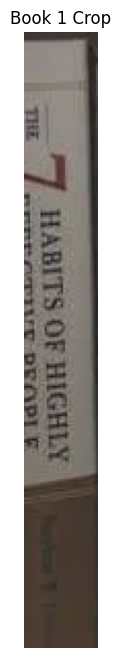

In [98]:
# Display the first crop

test_crop = book_crops[0]

print(
    "Crop shape:",
    test_crop.shape
)

plt.figure(figsize=(5, 8))

plt.imshow(
    cv2.cvtColor(
        test_crop,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("Book 1 Crop")
plt.show()

In [99]:
# Make sure PaddleOCR is initialized correctly

from paddleocr import PaddleOCR
import paddle

print(
    "PaddlePaddle version:",
    paddle.__version__
)

print(
    "Paddle device:",
    paddle.device.get_device()
)

print(
    "Paddle CUDA:",
    paddle.is_compiled_with_cuda()
)

PaddlePaddle version: 3.3.1
Paddle device: cpu
Paddle CUDA: False


In [100]:
ocr = PaddleOCR(
    lang="en",
    device="cpu",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=True,
    enable_mkldnn=False
)

print("PaddleOCR initialized successfully.")

Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


PaddleOCR initialized successfully.


In [102]:
# Resize the crop

def upscale_crop(
    crop,
    target_height=800
):

    if crop is None:
        raise ValueError(
            "Crop is None."
        )

    h, w = crop.shape[:2]

    if h == 0 or w == 0:
        raise ValueError(
            "Crop has zero dimensions."
        )

    if h >= target_height:
        return crop

    scale = (
        target_height / h
    )

    new_width = int(
        w * scale
    )

    return cv2.resize(
        crop,
        (
            new_width,
            target_height
        ),
        interpolation=cv2.INTER_CUBIC
    )


test_crop = upscale_crop(
    book_crops[0],
    target_height=800
)

print(
    "Resized crop:",
    test_crop.shape
)

Resized crop: (800, 95, 3)


In [103]:
print("Running PaddleOCR...")

test_result = ocr.predict(
    input=test_crop
)

print(
    "OCR prediction completed."
)

print(
    "Number of results:",
    len(test_result)
)

Running PaddleOCR...
OCR prediction completed.
Number of results: 1


In [104]:
print(
    type(test_result)
)

print(
    type(test_result[0])
)

<class 'list'>
<class 'paddlex.inference.pipelines.ocr.result.OCRResult'>


In [105]:
test_result[0].print()

{'res': {'input_path': None, 'page_index': None, 'model_settings': {'use_doc_preprocessor': False, 'use_textline_orientation': True}, 'dt_polys': array([[[  0,  88],
        ...,
        [  0, 144]],

       ...,

       [[  0, 410],
        ...,
        [  2, 545]]], dtype=int16), 'text_det_params': {'limit_side_len': 64, 'limit_type': 'min', 'thresh': 0.3, 'max_side_limit': 4000, 'box_thresh': 0.6, 'unclip_ratio': 1.5}, 'text_type': 'general', 'textline_orientation_angles': array([0, ..., 0]), 'text_rec_score_thresh': 0.0, 'return_word_box': False, 'rec_texts': ['THE', 'HABITS OF HIGHLY', 'PEOPLE'], 'rec_scores': array([0.99913996, ..., 0.96966654]), 'rec_polys': array([[[  0,  88],
        ...,
        [  0, 144]],

       ...,

       [[  0, 410],
        ...,
        [  2, 545]]], dtype=int16), 'rec_boxes': array([[  0, ..., 144],
       ...,
       [  0, ..., 545]], dtype=int16)}}


In [106]:
import json


def parse_ocr_result(result):

    data = result.json

    if isinstance(data, str):
        data = json.loads(data)

    if (
        isinstance(data, dict)
        and "res" in data
    ):
        data = data["res"]

    texts = data.get(
        "rec_texts",
        []
    )

    scores = data.get(
        "rec_scores",
        []
    )

    return {
        "texts": texts,
        "scores": scores
    }

In [107]:
parsed = parse_ocr_result(
    test_result[0]
)

print(
    "Texts:"
)

print(
    parsed["texts"]
)

print(
    "\nScores:"
)

print(
    parsed["scores"]
)

Texts:
['THE', 'HABITS OF HIGHLY', 'PEOPLE']

Scores:
[0.9991399645805359, 0.9900819063186646, 0.9696665406227112]


In [108]:
if parsed["texts"]:

    combined_text = " ".join(
        str(text).strip()
        for text in parsed["texts"]
        if str(text).strip()
    )

    confidence = float(
        np.mean(
            parsed["scores"]
        )
    )

else:

    combined_text = ""
    confidence = 0.0


print(
    "Detected text:",
    combined_text
)

print(
    "Average confidence:",
    round(
        confidence,
        3
    )
)

Detected text: THE HABITS OF HIGHLY PEOPLE
Average confidence: 0.986


In [109]:
print("Number of book crops:", len(book_crops))

if len(book_crops) == 0:
    raise ValueError(
        "book_crops is empty. Run the book-cropping cells first."
    )

Number of book crops: 12


In [110]:
import json
import numpy as np


def parse_ocr_result(result):

    data = result.json

    if isinstance(data, str):
        data = json.loads(data)

    if (
        isinstance(data, dict)
        and "res" in data
    ):
        data = data["res"]

    texts = data.get(
        "rec_texts",
        []
    )

    scores = data.get(
        "rec_scores",
        []
    )

    return {
        "texts": texts,
        "scores": scores
    }

In [111]:
def extract_text_from_result(
    result
):

    parsed = parse_ocr_result(
        result
    )

    texts = parsed["texts"]
    scores = parsed["scores"]

    clean_texts = []

    for text in texts:

        text = str(text).strip()

        if text:
            clean_texts.append(text)

    if clean_texts:
        combined_text = " ".join(
            clean_texts
        )
    else:
        combined_text = ""

    if scores:
        confidence = float(
            np.mean(scores)
        )
    else:
        confidence = 0.0

    return {
        "text": combined_text,
        "confidence": confidence
    }

In [112]:
def run_ocr(
    image
):

    try:

        results = ocr.predict(
            input=image
        )

        if not results:

            return {
                "text": "",
                "confidence": 0.0,
                "success": False
            }

        extracted = (
            extract_text_from_result(
                results[0]
            )
        )

        extracted["success"] = True

        return extracted

    except Exception as e:

        return {
            "text": "",
            "confidence": 0.0,
            "success": False,
            "error": str(e)
        }

In [113]:
import cv2


def upscale_crop(
    crop,
    target_height=800
):

    if crop is None:
        raise ValueError(
            "Crop is None."
        )

    h, w = crop.shape[:2]

    if h == 0 or w == 0:
        raise ValueError(
            "Crop has zero dimensions."
        )

    if h >= target_height:
        return crop

    scale = (
        target_height / h
    )

    new_width = int(
        w * scale
    )

    return cv2.resize(
        crop,
        (
            new_width,
            target_height
        ),
        interpolation=cv2.INTER_CUBIC
    )

In [114]:
def ocr_book_spine(
    crop,
    retry_threshold=0.75
):

    crop = upscale_crop(
        crop,
        target_height=800
    )

    # ---------------------------------
    # 1. Original orientation
    # ---------------------------------

    best = run_ocr(
        crop
    )

    best["orientation"] = (
        "original"
    )

    # If already good, stop.
    if (
        best["success"]
        and best["text"].strip()
        and
        best["confidence"]
        >= retry_threshold
    ):

        return best

    # ---------------------------------
    # 2. Rotate clockwise
    # ---------------------------------

    rotated_cw = cv2.rotate(
        crop,
        cv2.ROTATE_90_CLOCKWISE
    )

    result_cw = run_ocr(
        rotated_cw
    )

    if (
        result_cw["success"]
        and result_cw["text"].strip()
        and
        result_cw["confidence"]
        > best["confidence"]
    ):

        best = {
            **result_cw,
            "orientation":
                "90_clockwise"
        }

    # ---------------------------------
    # 3. Rotate counter-clockwise
    # ---------------------------------

    rotated_ccw = cv2.rotate(
        crop,
        cv2.ROTATE_90_COUNTERCLOCKWISE
    )

    result_ccw = run_ocr(
        rotated_ccw
    )

    if (
        result_ccw["success"]
        and result_ccw["text"].strip()
        and
        result_ccw["confidence"]
        > best["confidence"]
    ):

        best = {
            **result_ccw,
            "orientation":
                "90_counterclockwise"
        }

    return best

In [115]:
from tqdm.auto import tqdm

ocr_outputs = []

for book_number, crop in enumerate(
    tqdm(
        book_crops,
        desc="Reading book spines"
    ),
    start=1
):

    result = ocr_book_spine(
        crop
    )

    result["book_number"] = (
        book_number
    )

    ocr_outputs.append(
        result
    )

print(
    f"\nOCR completed for "
    f"{len(ocr_outputs)} books."
)

Reading book spines:   0%|          | 0/12 [00:00<?, ?it/s]


OCR completed for 12 books.


In [116]:
for result in ocr_outputs:

    print(
        f"\nBook {result['book_number']}"
    )

    print(
        "Text:",
        result["text"]
    )

    print(
        "Confidence:",
        round(
            result["confidence"],
            3
        )
    )

    print(
        "Orientation:",
        result["orientation"]
    )

    print(
        "Success:",
        result["success"]
    )

    print(
        "-" * 70
    )


Book 1
Text: THE HABITS OF HIGHLY PEOPLE
Confidence: 0.986
Orientation: original
Success: True
----------------------------------------------------------------------

Book 2
Text: HOW TO WIN FRIENDS INFLUENCE PEOPLE 8 CARNEGIE DALE
Confidence: 0.868
Orientation: original
Success: True
----------------------------------------------------------------------

Book 3
Text: The PsychologyMoney MORGAN HOUSEL
Confidence: 0.992
Orientation: original
Success: True
----------------------------------------------------------------------

Book 4
Text: THE COURAGE TO BE DISLIKED ICHIRO KISHUMY and FUMITASE KOGA
Confidence: 0.909
Orientation: original
Success: True
----------------------------------------------------------------------

Book 5
Text: k and g rich Napoleon Hill
Confidence: 0.916
Orientation: 90_clockwise
Success: True
----------------------------------------------------------------------

Book 6
Text: WHO MOVED MYCHEESE? LEL SPEN,TLJONNSON
Confidence: 0.775
Orientation: 90_counterclockw

In [117]:
ocr_df = pd.DataFrame(
    [
        {
            "book_number":
                result["book_number"],

            "ocr_text":
                result["text"],

            "ocr_confidence":
                round(
                    result["confidence"],
                    3
                ),

            "orientation":
                result["orientation"],

            "success":
                result["success"]
        }

        for result in ocr_outputs
    ]
)

ocr_df

,book_number,ocr_text,ocr_confidence,orientation,success
0,1,THE HABITS OF HIGHLY PEOPLE,0.986,original,True
1,2,HOW TO WIN FRIENDS INFLUENCE PEOPLE 8 CARNEGIE...,0.868,original,True
2,3,The PsychologyMoney MORGAN HOUSEL,0.992,original,True
3,4,THE COURAGE TO BE DISLIKED ICHIRO KISHUMY and ...,0.909,original,True
4,5,k and g rich Napoleon Hill,0.916,90_clockwise,True
5,6,"WHO MOVED MYCHEESE? LEL SPEN,TLJONNSON",0.775,90_counterclockwise,True
6,7,GRITANGELADUCKWORTH,1.000,original,True
7,8,UNESONYOURSELF,0.910,90_counterclockwise,True
8,9,GOOD VIRES. GOOD LIFE VEENIND,0.835,90_counterclockwise,True
9,10,Atomic Habits James Clear rh,0.953,original,True


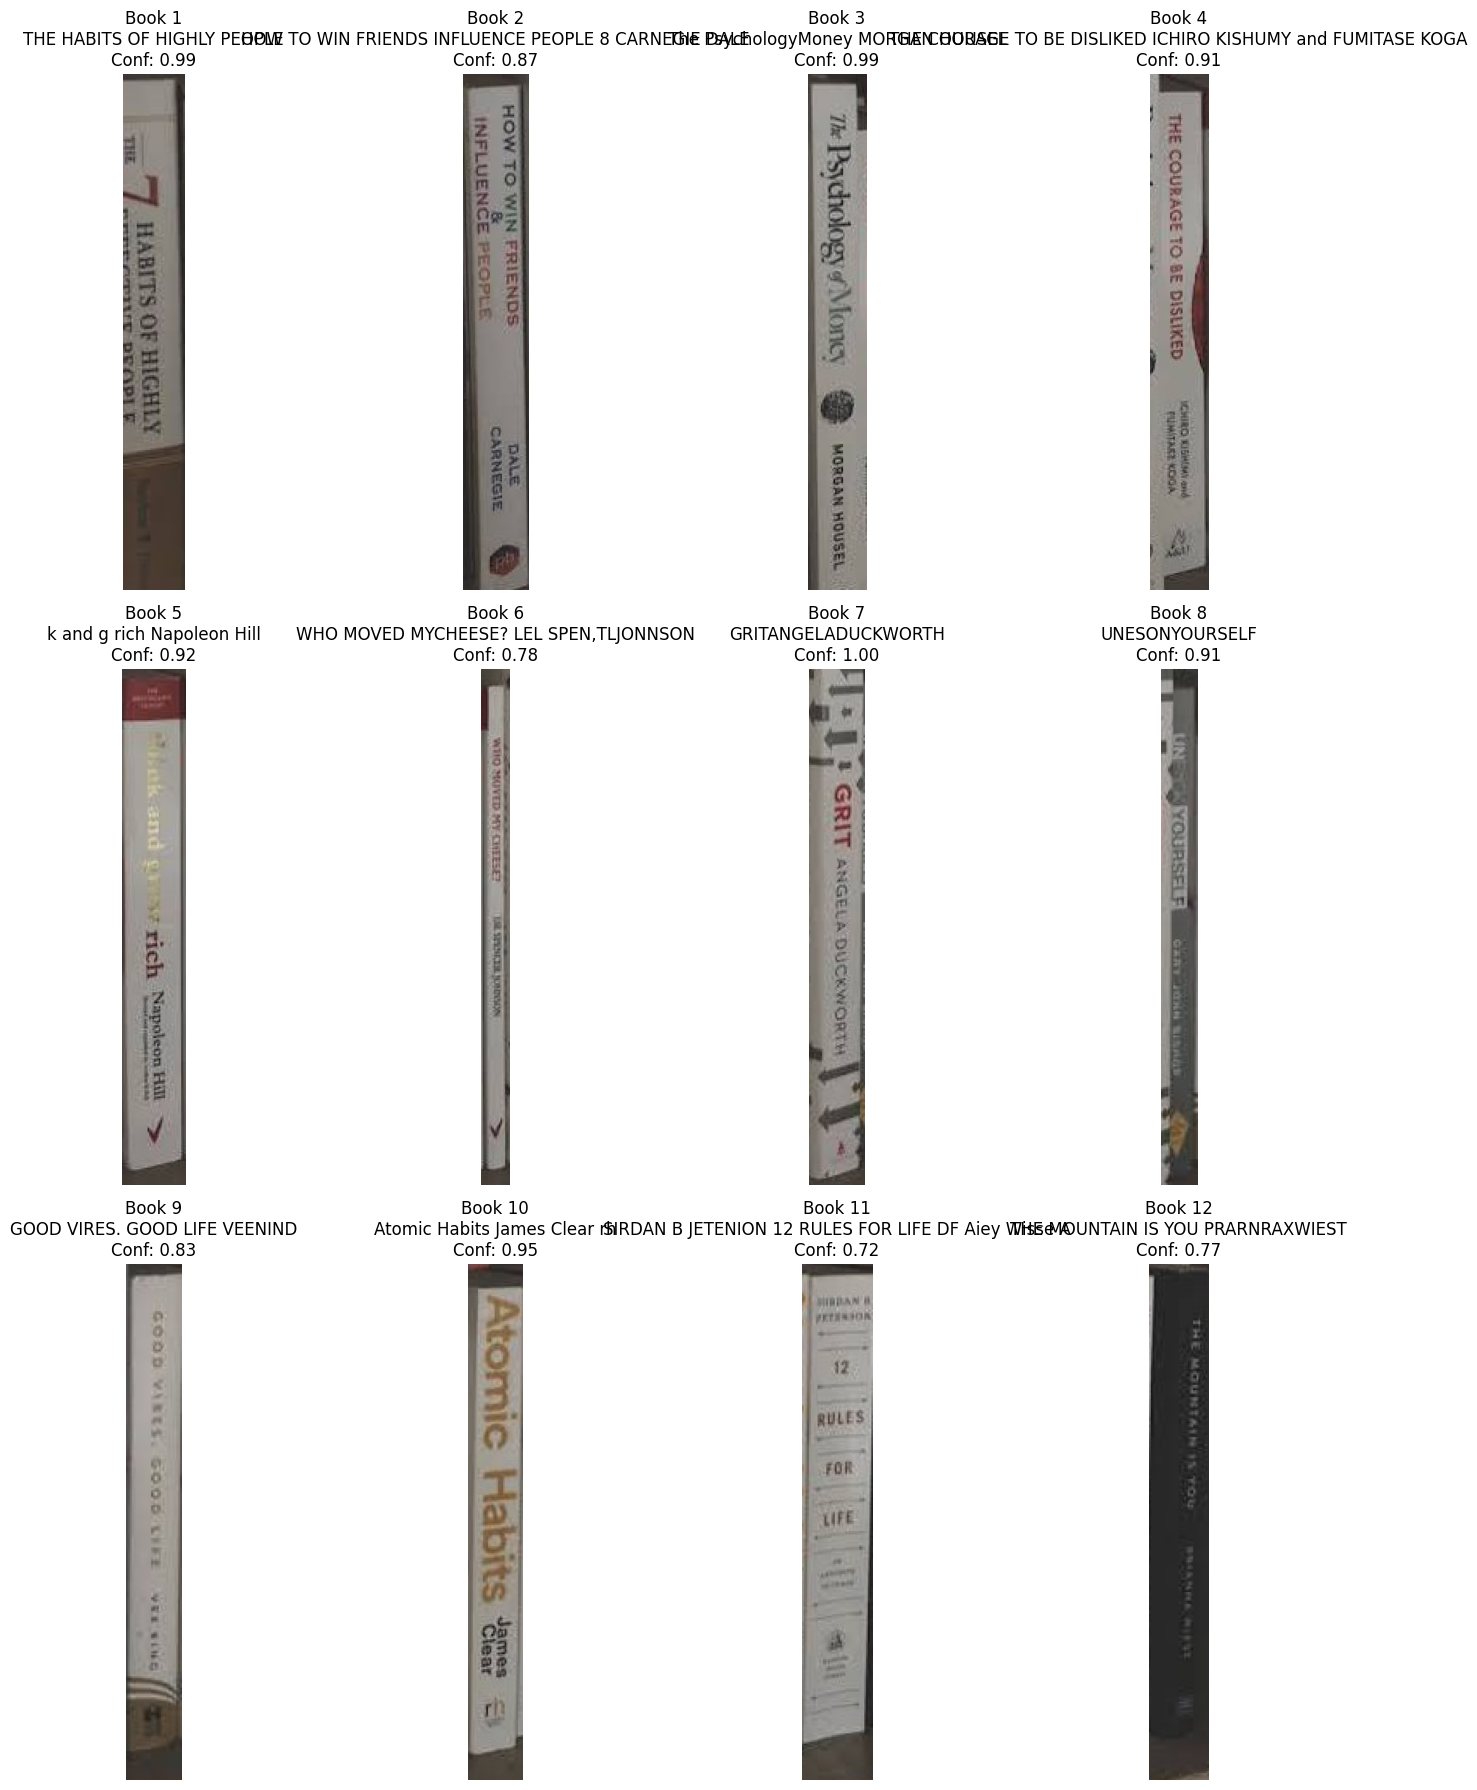

In [118]:
columns = 4
rows = math.ceil(
    len(book_crops) / columns
)

plt.figure(
    figsize=(
        columns * 4,
        rows * 6
    )
)

for i, crop in enumerate(
    book_crops
):

    crop_rgb = cv2.cvtColor(
        crop,
        cv2.COLOR_BGR2RGB
    )

    ax = plt.subplot(
        rows,
        columns,
        i + 1
    )

    ax.imshow(
        crop_rgb
    )

    text = (
        ocr_outputs[i]["text"]
    )

    confidence = (
        ocr_outputs[i]["confidence"]
    )

    if not text:
        text = "No text detected"

    # Keep the title readable.
    text = text[:80]

    ax.set_title(
        f"Book {i+1}\n"
        f"{text}\n"
        f"Conf: {confidence:.2f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
from pathlib import Path

In [44]:
# Your actual training output folder
BEST_MODEL_PATH = (
    Path("/content/runs")
    / "book_spine_segmentation"
    / "weights"
    / "best.pt"
)

print("Best model path:")
print(BEST_MODEL_PATH)

print("\nExists:")
print(BEST_MODEL_PATH.exists())

Best model path:
/content/runs/book_spine_segmentation/weights/best.pt

Exists:
True


In [45]:
# Search the entire /content directory for best.pt
best_models = list(
    Path("/content").rglob("best.pt")
)

print("Number of best.pt files found:", len(best_models))

for path in best_models:
    print(path)

Number of best.pt files found: 1
/content/runs/book_spine_segmentation/weights/best.pt


In [46]:
from pathlib import Path
import os
import shutil
import json
import random
import math

BASE_DIR = Path("/content")

print("Contents of /content:")
for item in BASE_DIR.iterdir():
    print(item)

Contents of /content:
/content/.config
/content/books-1.zip
/content/book_spines.yaml
/content/runs
/content/weights
/content/data
/content/models
/content/yolo26n-seg.pt
/content/outputs
/content/sample_data


In [47]:
all_pt_files = list(
    BASE_DIR.rglob("*.pt")
)

print(
    "Number of .pt files found:",
    len(all_pt_files)
)

for path in all_pt_files:
    print(path)

Number of .pt files found: 4
/content/yolo26n-seg.pt
/content/weights/yolo26n.pt
/content/runs/book_spine_segmentation/weights/best.pt
/content/runs/book_spine_segmentation/weights/last.pt


In [48]:
from pathlib import Path

print("Dataset root:")
print(DATASET_ROOT)

print("\nYAML file:")
print(yaml_path)

print("\nYAML contents:")
print(yaml_path.read_text())

Dataset root:
/content/data/books_dataset/books-1

YAML file:
/content/book_spines.yaml

YAML contents:
path: /content/data/books_dataset/books-1

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine


In [49]:
from pathlib import Path

BASE_DIR = Path("/content")

print("Files and folders in /content:\n")

for item in BASE_DIR.iterdir():
    print(item)

Files and folders in /content:

/content/.config
/content/books-1.zip
/content/book_spines.yaml
/content/runs
/content/weights
/content/data
/content/models
/content/yolo26n-seg.pt
/content/outputs
/content/sample_data


In [50]:
zip_files = list(
    BASE_DIR.glob("*.zip")
)

print(
    "ZIP files found:",
    len(zip_files)
)

for path in zip_files:
    print(path)

ZIP files found: 1
/content/books-1.zip


In [51]:
import zipfile
import shutil

ZIP_PATH = zip_files[0]

EXTRACT_DIR = (
    BASE_DIR / "dataset"
)

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)

EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as zip_ref:

    zip_ref.extractall(
        EXTRACT_DIR
    )

print(
    "Dataset extracted to:"
)

print(
    EXTRACT_DIR
)

Dataset extracted to:
/content/dataset


In [52]:
def find_dataset_root(base_dir):

    candidates = []

    for path in base_dir.rglob("*"):

        if not path.is_dir():
            continue

        required_folders = [
            path / "train",
            path / "valid",
            path / "test"
        ]

        if all(
            folder.exists()
            for folder in required_folders
        ):
            candidates.append(path)

    if not candidates:
        raise FileNotFoundError(
            "Could not find a folder containing "
            "train, valid and test."
        )

    candidates.sort(
        key=lambda p: len(p.parts)
    )

    return candidates[0]


DATASET_ROOT = find_dataset_root(
    EXTRACT_DIR
)

print(
    "Dataset root:"
)

print(
    DATASET_ROOT
)

Dataset root:
/content/dataset/books-1


In [53]:
for split in [
    "train",
    "valid",
    "test"
]:

    images_dir = (
        DATASET_ROOT
        / split
        / "images"
    )

    labels_dir = (
        DATASET_ROOT
        / split
        / "labels"
    )

    print(
        f"\n{split.upper()}"
    )

    print(
        "Images folder:",
        images_dir.exists()
    )

    print(
        "Labels folder:",
        labels_dir.exists()
    )

    print(
        "Number of images:",
        len(list(images_dir.iterdir()))
    )

    print(
        "Number of labels:",
        len(list(labels_dir.glob("*.txt")))
    )


TRAIN
Images folder: True
Labels folder: True
Number of images: 422
Number of labels: 422

VALID
Images folder: True
Labels folder: True
Number of images: 119
Number of labels: 119

TEST
Images folder: True
Labels folder: True
Number of images: 69
Number of labels: 69


In [54]:
yaml_path = (
    BASE_DIR /
    "book_spines_seg.yaml"
)

yaml_content = f"""
path: {DATASET_ROOT}

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine
"""

yaml_path.write_text(
    yaml_content.strip(),
    encoding="utf-8"
)

print(
    yaml_path.read_text(
        encoding="utf-8"
    )
)

path: /content/dataset/books-1

train: train/images
val: valid/images
test: test/images

names:
  0: book_spine


In [55]:
OUTPUT_DIR = (
    BASE_DIR / "outputs"
)

MODEL_DIR = (
    BASE_DIR / "models"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "OUTPUT_DIR:",
    OUTPUT_DIR
)

print(
    "MODEL_DIR:",
    MODEL_DIR
)

OUTPUT_DIR: /content/outputs
MODEL_DIR: /content/models


In [56]:
def validate_segmentation_label(
    label_path
):

    lines = (
        label_path
        .read_text()
        .splitlines()
    )

    for line_number, line in enumerate(
        lines,
        start=1
    ):

        if not line.strip():
            continue

        parts = line.split()

        # class ID + at least 3 (x,y) pairs
        if len(parts) < 7:

            return False, (
                f"Line {line_number}: "
                "too few values"
            )

        # coordinates must come in x,y pairs
        if (len(parts) - 1) % 2 != 0:

            return False, (
                f"Line {line_number}: "
                "invalid coordinate count"
            )

        try:

            class_id = int(
                float(parts[0])
            )

            coordinates = [
                float(x)
                for x in parts[1:]
            ]

        except ValueError:

            return False, (
                f"Line {line_number}: "
                "non-numeric value"
            )

        if class_id != 0:

            return False, (
                f"Line {line_number}: "
                f"class {class_id}, expected 0"
            )

        if not all(
            0 <= value <= 1
            for value in coordinates
        ):

            return False, (
                f"Line {line_number}: "
                "coordinate outside [0,1]"
            )

    return True, "Valid"

In [57]:
sample_labels = list(
    (
        DATASET_ROOT
        / "train"
        / "labels"
    ).glob("*.txt")
)

print(
    "Training label files:",
    len(sample_labels)
)

sample_label = sample_labels[0]

valid, message = (
    validate_segmentation_label(
        sample_label
    )
)

print(
    "\nSample label:"
)

print(
    sample_label
)

print(
    "\nValidation:"
)

print(
    message
)

Training label files: 422

Sample label:
/content/dataset/books-1/train/labels/crop-344_png.rf.9ce23e94f42d8d50cfceafaa64808515.txt

Validation:
Valid


In [58]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

train_images_dir = (
    DATASET_ROOT
    / "train"
    / "images"
)

train_labels_dir = (
    DATASET_ROOT
    / "train"
    / "labels"
)

train_images = [
    p
    for p in train_images_dir.iterdir()
    if p.suffix.lower()
    in {".jpg", ".jpeg", ".png", ".webp"}
]

sample_image = random.choice(
    train_images
)

sample_label = (
    train_labels_dir
    / f"{sample_image.stem}.txt"
)

print(
    "Image:",
    sample_image.name
)

print(
    "Label:",
    sample_label.name
)

Image: crop-288_png.rf.64e954277de6ad7cdc7e34300efb599f.jpg
Label: crop-288_png.rf.64e954277de6ad7cdc7e34300efb599f.txt


In [59]:
def draw_segmentation_annotations(
    image_path,
    label_path
):

    image = cv2.imread(
        str(image_path)
    )

    if image is None:
        raise ValueError(
            "Could not load image."
        )

    h, w = image.shape[:2]

    lines = (
        label_path
        .read_text()
        .splitlines()
    )

    for index, line in enumerate(
        lines,
        start=1
    ):

        if not line.strip():
            continue

        parts = line.split()

        if len(parts) < 7:
            continue

        coords = np.array(
            [
                float(x)
                for x in parts[1:]
            ],
            dtype=np.float32
        )

        points = coords.reshape(
            -1,
            2
        )

        points[:, 0] *= w
        points[:, 1] *= h

        points = points.astype(
            np.int32
        )

        cv2.polylines(
            image,
            [points],
            True,
            (0, 255, 0),
            3
        )

        center = (
            points
            .mean(axis=0)
            .astype(np.int32)
        )

        cv2.putText(
            image,
            f"Book {index}",
            tuple(center),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    return image

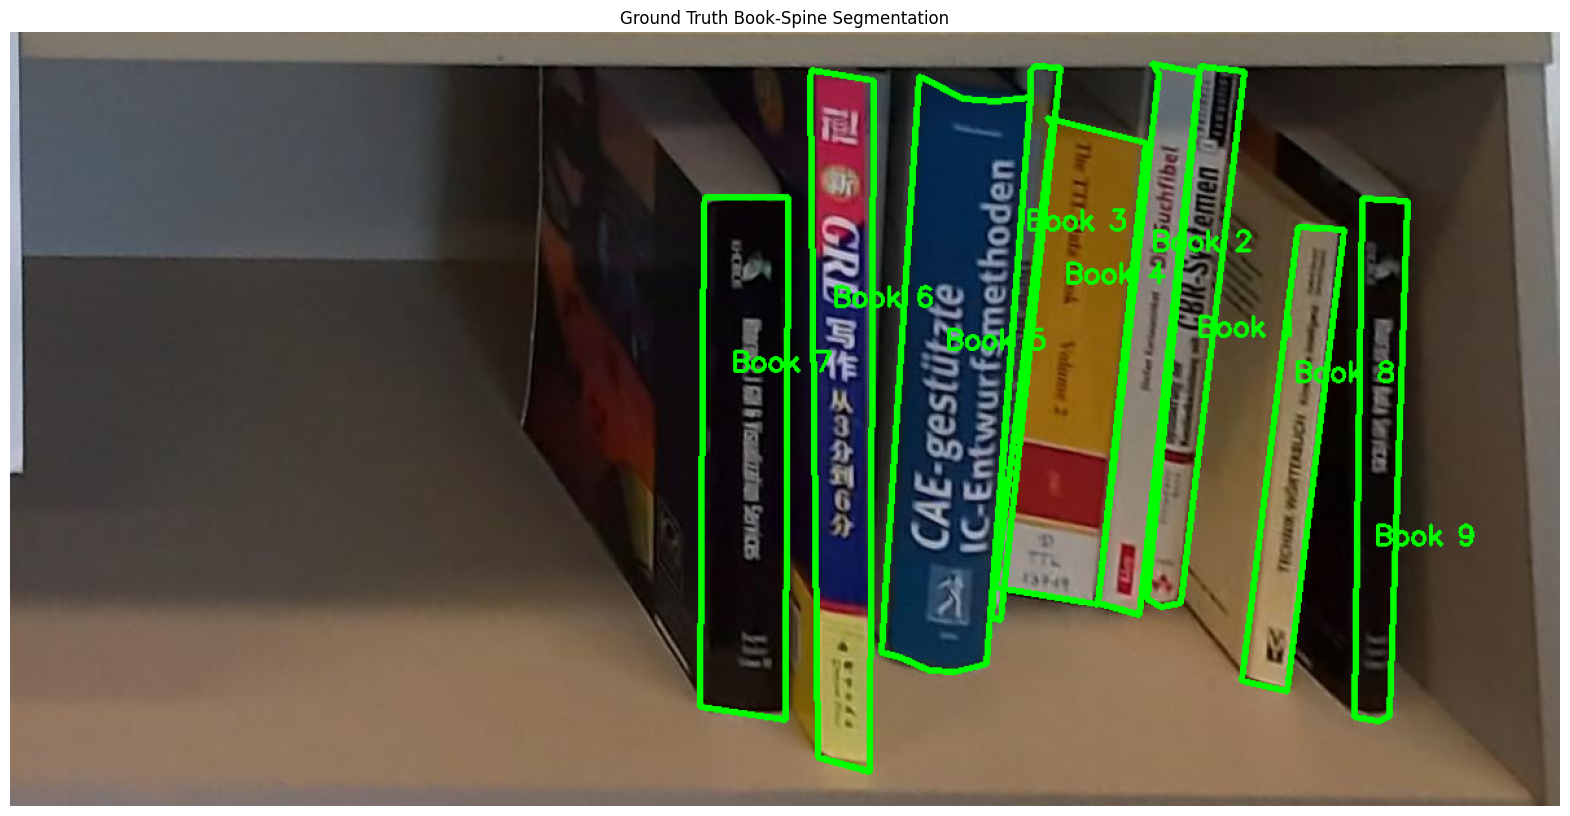

In [60]:
annotated = (
    draw_segmentation_annotations(
        sample_image,
        sample_label
    )
)

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(
    figsize=(20, 12)
)

plt.imshow(
    annotated_rgb
)

plt.axis("off")

plt.title(
    "Ground Truth Book-Spine Segmentation"
)

plt.show()

In [61]:
from ultralytics import YOLO
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

CUDA available: True
GPU: Tesla T4


In [62]:
model = YOLO(
    "yolo26n-seg.pt"
)

print(
    "Model task:",
    model.task
)

Model task: segment


In [63]:
EPOCHS = 100
IMG_SIZE = 960

train_results = model.train(

    data=str(
        yaml_path
    ),

    epochs=EPOCHS,

    imgsz=IMG_SIZE,

    batch=-1,

    device=0,

    patience=20,

    workers=2,

    cache=False,

    amp=True,

    seed=42,

    project="/content/runs",

    name="book_spine_segmentation",

    exist_ok=True,

    plots=True
)

Ultralytics 8.4.166 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/book_spines_seg.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=book_spine_segmentation, nbs=64, nms=None, opset=None, 

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

Exception ignored in atexit callback <function _exit_function at 0x7f18c07422a0>:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/util.py", line 405, in _exit_function
    _run_finalizers(0)
  File "/usr/lib/python3.13/multiprocessing/util.py", line 371, in _run_finalizers
    finalizer()
  File "/usr/lib/python3.13/multiprocessing/util.py", line 295, in __call__
    res = self._callback(*self._args, **self._kwargs)
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 227, in _finalize_close
    notempty.notify()
  File "/usr/lib/python3.13/threading.py", line 414, in notify
    waiter.release()
KeyboardInterrupt: 


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_5956/4150210966.py", line 4, in <cell line: 0>
    train_results = model.train(
    
    ...<28 lines>...
        plots=True
    )
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/model.py", line 894, in train
    self.trainer.train()
    ~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 257, in train
    self._do_train()
    ~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 541, in _do_train
    loss, self.loss_items = self.model(batch)
                            ~~~~~~~~~~^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    

TypeError: object of type 'NoneType' has no len()